In [1]:
!pip install -q -U ultralytics peft bitsandbytes transformers accelerate huggingface_hub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 22.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 680.7/680.7 kB 41.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 29.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 104.6 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.7/383.7 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 646.8/646.8 kB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 110.7 MB/s eta 0:00:0000:01


In [2]:
import os
import random
from pathlib import Path
from contextlib import nullcontext

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torch.amp import autocast, GradScaler

import albumentations as A
from tqdm.auto import tqdm

from peft import get_peft_model, LoraConfig
from transformers import Sam3Model

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = True
torch.backends.cudnn.deterministic = False
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Torch: {torch.__version__} | Device: {device}")
if torch.cuda.is_available():
    gpu = torch.cuda.get_device_name(0)
    vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"GPU: {gpu} | VRAM: {vram_gb:.1f} GB")

Torch: 2.10.0+cu128 | Device: cuda
GPU: Tesla T4 | VRAM: 14.6 GB


In [3]:
DATA_DIR =  Path("/kaggle/input/datasets/nabinpoudelsir/road-kathmandu-manually")
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# print(f"Data is located at: {path}")
# print("Contents:", os.listdir(path))
print(f"Training data is located at: {TRAIN_DIR}")
print(f"Validation data is located at: {VAL_DIR}")
print(f"Testing data is located at: {TEST_DIR}")
print("Contents:", os.listdir(TRAIN_DIR))

Training data is located at: /kaggle/input/datasets/nabinpoudelsir/road-kathmandu-manually/train
Validation data is located at: /kaggle/input/datasets/nabinpoudelsir/road-kathmandu-manually/val
Testing data is located at: /kaggle/input/datasets/nabinpoudelsir/road-kathmandu-manually/test
Contents: ['images', 'masks']


In [4]:
SAM3_INPUT_SIZE = 504  # True memory-friendly size for 16 GB; change to 1024 only with batch=1 + grad checkpointing

train_transform = A.Compose([
    A.Resize(height=SAM3_INPUT_SIZE, width=SAM3_INPUT_SIZE),

    # Lighting
    A.RandomBrightnessContrast(p=0.5),
    A.CLAHE(p=0.2),

    # Orientation invariance — lossless 90° first, then continuous
    A.RandomRotate90(p=0.75),
    A.Rotate(limit=45, p=0.4),          # narrowed: 180° is overkill after RandomRotate90

    # Scale + translation (no rotate; handled above)
    A.ShiftScaleRotate(
        shift_limit=0.05, scale_limit=0.15,
        rotate_limit=0, p=0.4
    ),

    # Blur + noise
    A.OneOf([
        A.MotionBlur(p=1.0),
        A.GaussianBlur(p=1.0),
    ], p=0.3),
    A.GaussNoise(std_range=(0.02, 0.08), p=0.3),  # updated API

    # GSD variation simulation
    A.Downscale(scale_range=(0.5, 0.9), p=0.3),   # updated API

    # Geometric distortion
    A.GridDistortion(p=0.2),

    # Flips
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
])

/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [5]:
test_transform = A.Compose([
    A.Resize(height=SAM3_INPUT_SIZE, width=SAM3_INPUT_SIZE),
])

In [6]:
class ImageSegmentationDataset(Dataset):
    SUPPORTED_IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
    SUPPORTED_MASK_EXTS  = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    def __init__(self, base_dir, split, transform=None):
        super().__init__()
        self.split_dir = Path(base_dir) / split
        self.image_dir = self.split_dir / "images"
        self.mask_dir  = self.split_dir / "masks"
        self.transform = transform

        if not self.image_dir.exists():
            raise FileNotFoundError(f"Missing image directory: {self.image_dir}")
        if not self.mask_dir.exists():
            raise FileNotFoundError(f"Missing mask directory: {self.mask_dir}")

        # Index masks by stem → path (any supported extension)
        self.mask_paths = {
            p.stem: p
            for p in self.mask_dir.iterdir()
            if p.is_file() and p.suffix.lower() in self.SUPPORTED_MASK_EXTS
        }

        # Collect images whose stems have a matching mask
        self.image_filenames = sorted([
            p.name
            for p in self.image_dir.iterdir()
            if p.is_file()
            and p.suffix.lower() in self.SUPPORTED_IMAGE_EXTS
            and p.stem in self.mask_paths
        ])

        if len(self.image_filenames) == 0:
            raise RuntimeError(f"No valid image-mask pairs found in split: {split}")

    def __len__(self):
        return len(self.image_filenames)

    def _read_image(self, path: Path) -> np.ndarray:
        """Read an image as RGB uint8, supporting TIFF (including multi-band) via rasterio."""
        if path.suffix.lower() in {".tif", ".tiff"}:
            import rasterio
            with rasterio.open(path) as src:
                if src.count >= 3:
                    # Read first three bands → (3, H, W) → (H, W, 3)
                    arr = src.read([1, 2, 3]).transpose(1, 2, 0)
                else:
                    # Single-band TIFF: replicate to RGB
                    band = src.read(1)
                    arr  = np.stack([band, band, band], axis=-1)
            # Normalise to uint8 if needed (e.g. 16-bit GeoTIFF)
            if arr.dtype != np.uint8:
                arr = arr.astype(np.float32)
                lo, hi = arr.min(), arr.max()
                arr = ((arr - lo) / (hi - lo + 1e-6) * 255).astype(np.uint8)
            return arr  # already RGB
        else:
            bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
            if bgr is None:
                raise RuntimeError(f"Failed to read image: {path}")
            return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

    def _read_mask(self, path: Path) -> np.ndarray:
        """Read a mask as grayscale uint8, supporting TIFF via rasterio."""
        if path.suffix.lower() in {".tif", ".tiff"}:
            import rasterio
            with rasterio.open(path) as src:
                mask = src.read(1)
            if mask.dtype != np.uint8:
                mask = (mask > 0).astype(np.uint8) * 255
            return mask
        else:
            mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
            if mask is None:
                raise RuntimeError(f"Failed to read mask: {path}")
            return mask

    def __getitem__(self, idx):
        img_name  = self.image_filenames[idx]
        img_path  = self.image_dir / img_name
        mask_path = self.mask_paths[img_path.stem]

        image_rgb = self._read_image(img_path)
        mask      = self._read_mask(mask_path)

        if self.transform is not None:
            transformed = self.transform(image=image_rgb, mask=mask)
            image_rgb   = transformed["image"]
            mask        = transformed["mask"]

        image_tensor = torch.from_numpy(image_rgb).permute(2, 0, 1).float() / 255.0
        mask_tensor  = torch.from_numpy((mask > 0).astype(np.float32)).unsqueeze(0)

        return image_tensor, mask_tensor

In [7]:
import rasterio

In [8]:
train_dataset = ImageSegmentationDataset(base_dir=DATA_DIR, split="train", transform=train_transform)
val_dataset = ImageSegmentationDataset(base_dir=DATA_DIR, split="val", transform=test_transform)
test_dataset = ImageSegmentationDataset(base_dir=DATA_DIR, split="test", transform=test_transform)

print(f"Training Dataset: {len(train_dataset)} Images")
print(f"Validation Dataset: {len(val_dataset)} Images")
print(f"Testing Dataset: {len(test_dataset)} Images")
print(f"SAM3 input size: {SAM3_INPUT_SIZE}x{SAM3_INPUT_SIZE}")

Training Dataset: 575 Images
Validation Dataset: 191 Images
Testing Dataset: 225 Images
SAM3 input size: 504x504


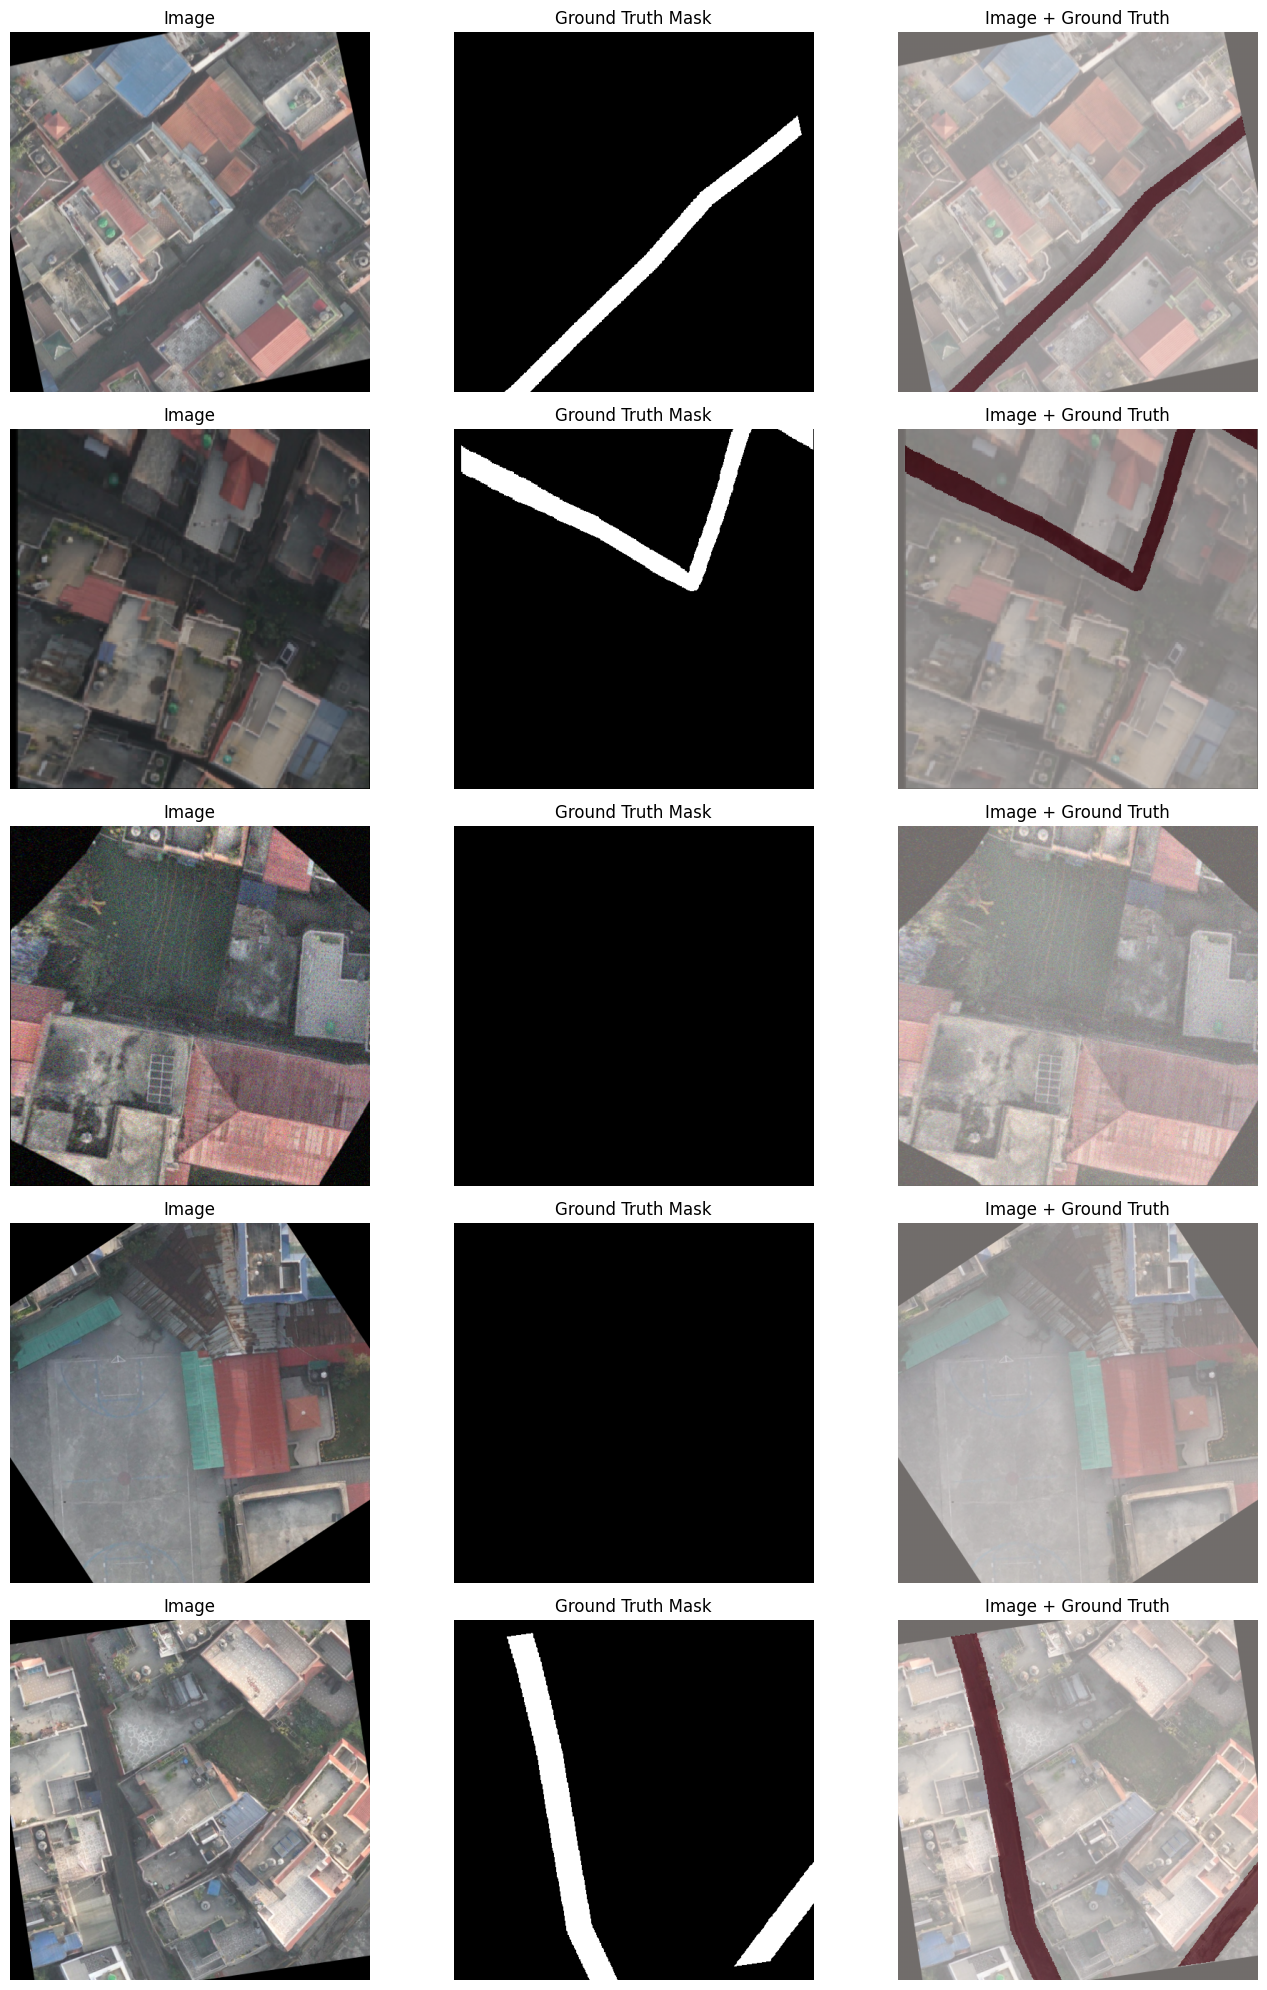

In [9]:
def show_image(num_images=5):
    num_images = min(num_images, len(train_dataset))
    fig, ax = plt.subplots(num_images, 3, figsize=(14, 4 * num_images))
    if num_images == 1:
        ax = np.expand_dims(ax, axis=0)

    for i in range(num_images):
        image, mask = train_dataset[i]
        image_np = image.permute(1, 2, 0).cpu().numpy()
        mask_np = mask.squeeze(0).cpu().numpy()

        ax[i, 0].imshow(image_np)
        ax[i, 0].set_title("Image")
        ax[i, 0].axis("off")

        ax[i, 1].imshow(mask_np, cmap="gray")
        ax[i, 1].set_title("Ground Truth Mask")
        ax[i, 1].axis("off")

        ax[i, 2].imshow(image_np)
        ax[i, 2].imshow(mask_np, alpha=0.45, cmap="Reds")
        ax[i, 2].set_title("Image + Ground Truth")
        ax[i, 2].axis("off")

    plt.tight_layout()
    plt.show()

show_image(5)

In [10]:
BATCH_SIZE = max(1, torch.cuda.device_count() * 1) if torch.cuda.is_available() else 1
# Set NUM_WORKERS to 0 to avoid PyTorch multiprocessing issues in Jupyter notebooks on Windows
NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

loader_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": PIN_MEMORY,
    "drop_last": False,
}
if NUM_WORKERS > 0:
    loader_kwargs["persistent_workers"] = True
    loader_kwargs["prefetch_factor"] = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **loader_kwargs,
    )

val_loader = DataLoader(
    val_dataset,
    batch_size=1, # validation can use batch size 1 generally, or match testing
    shuffle=False,
    **loader_kwargs,
    )

test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    **loader_kwargs,
    )

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

Train batches: 288 | Val batches: 191 | Test batches: 225


In [21]:
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

def enable_gradient_checkpointing_fallback(module: nn.Module) -> bool:
    # Do not force per-layer flags for SAM3: it can create an invalid partial state
    # where _gradient_checkpointing_func is missing in some layers.
    if hasattr(module, "gradient_checkpointing_enable"):
        try:
            module.gradient_checkpointing_enable()
            return True
        except (ValueError, TypeError, AttributeError):
            return False
    return False

def resolve_backbone_embed_dim(sam_model, vision_backbone) -> int:
    candidates = [
        getattr(getattr(vision_backbone, "config", None), "hidden_size", None),
        getattr(getattr(sam_model, "config", None), "hidden_size", None),
        getattr(getattr(getattr(sam_model, "config", None), "vision_config", None), "hidden_size", None),
    ]
    for value in candidates:
        if isinstance(value, int) and value > 0:
            return value
    return 1024

try:
    user_secrets = UserSecretsClient()
    hf_token = user_secrets.get_secret("HF_TOKEN")
    if hf_token:
        login(token=hf_token)
except Exception as e:
    print(f"Could not load HF_TOKEN from Kaggle Secrets: {e}")

model_kwargs = {
    "torch_dtype": torch.float16 if torch.cuda.is_available() else torch.float32,
}
try:
    sam_model = Sam3Model.from_pretrained(
        "facebook/sam3",
        image_size=SAM3_INPUT_SIZE,
        attn_implementation="eager",
        **model_kwargs,
    )
except TypeError:
    sam_model = Sam3Model.from_pretrained(
        "facebook/sam3",
        image_size=SAM3_INPUT_SIZE,
        **model_kwargs,
    )

vision_backbone = sam_model.vision_encoder
BACKBONE_EMBED_DIM = resolve_backbone_embed_dim(sam_model, vision_backbone)
gc_enabled = enable_gradient_checkpointing_fallback(vision_backbone)

print(f"Loaded SAM3 vision backbone at image_size={SAM3_INPUT_SIZE}. Gradient checkpointing enabled: {gc_enabled}")
print(f"Resolved backbone embed dim: {BACKBONE_EMBED_DIM}")

Loading weights:   0%|          | 0/1468 [00:00<?, ?it/s]

Loaded SAM3 vision backbone at image_size=504. Gradient checkpointing enabled: False
Resolved backbone embed dim: 1024


In [22]:
class UnpromptedSAMSegmenter(nn.Module):
    def __init__(self, backbone, embed_dim, num_classes=1):
        super().__init__()
        self.backbone = backbone

        if not isinstance(embed_dim, int) or embed_dim <= 0:
            raise RuntimeError("embed_dim must be a positive integer for SAM3 backbone outputs.")

        self.mask_head = nn.Sequential(
            nn.Conv2d(embed_dim, 128, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(64, num_classes, kernel_size=1),
        )

    def _reshape_features(self, features: torch.Tensor) -> torch.Tensor:
        if features.ndim == 4:
            return features
        if features.ndim == 3:
            b, n, c = features.shape
            side = int(np.sqrt(n))
            if side * side != n:
                raise RuntimeError(f"Cannot reshape sequence length {n} into square feature map")
            return features.transpose(1, 2).contiguous().view(b, c, side, side)
        raise RuntimeError(f"Unexpected backbone feature shape: {tuple(features.shape)}")

    def forward(self, pixel_values):
        # PEFT wrapper can inject conflicting kwargs for SAM3; call the wrapped base model directly.
        if hasattr(self.backbone, "base_model"):
            backbone_outputs = self.backbone.base_model(pixel_values=pixel_values)
        else:
            backbone_outputs = self.backbone(pixel_values=pixel_values)

        features = backbone_outputs.last_hidden_state
        features = self._reshape_features(features)
        
        # Ensure features dtype matches mask_head weights to avoid float16 vs float32 mismatches
        # Workaround DataParallel StopIteration generator error by directly accessing weight parameter
        target_dtype = self.mask_head[0].weight.dtype
        features = features.to(target_dtype)
        
        logits = self.mask_head(features)
        return logits

In [14]:
pip install -U torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 37.8 MB/s eta 0:00:0000:0100:01
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.


In [17]:
# Run this in a cell to see the real structure
print(type(sam_model))
print([name for name, _ in sam_model.named_children()])

<class 'transformers.models.sam3.modeling_sam3.Sam3Model'>
['vision_encoder', 'text_encoder', 'text_projection', 'geometry_encoder', 'detr_encoder', 'detr_decoder', 'mask_decoder', 'dot_product_scoring']


In [18]:
for name, module in sam_model.named_children():
    print(f"{name}: {type(module).__name__}")

vision_encoder: Sam3VisionModel
text_encoder: CLIPTextModelWithProjection
text_projection: Linear
geometry_encoder: Sam3GeometryEncoder
detr_encoder: Sam3DetrEncoder
detr_decoder: Sam3DetrDecoder
mask_decoder: Sam3MaskDecoder
dot_product_scoring: Sam3DotProductScoring


In [20]:
import inspect

print("=== detr_decoder ===")
print(inspect.signature(sam_model.detr_decoder.forward))

print("\n=== mask_decoder ===")
print(inspect.signature(sam_model.mask_decoder.forward))

print("\n=== geometry_encoder ===")
print(inspect.signature(sam_model.geometry_encoder.forward))
print("\n=== Sam3Model.forward ===")
print(inspect.signature(sam_model.forward))

=== detr_decoder ===
(vision_features: torch.Tensor, text_features: torch.Tensor, vision_pos_encoding: torch.Tensor, text_mask: torch.Tensor | None = None, spatial_shapes: torch.Tensor | None = None, **kwargs: Unpack[transformers.utils.generic.TransformersKwargs]) -> tuple | transformers.models.sam3.modeling_sam3.Sam3DETRDecoderOutput

=== mask_decoder ===
(decoder_queries: torch.Tensor, backbone_features: list[torch.Tensor], encoder_hidden_states: torch.Tensor, prompt_features: torch.Tensor | None = None, prompt_mask: torch.Tensor | None = None, **kwargs: Unpack[transformers.utils.generic.TransformersKwargs]) -> tuple | transformers.models.sam3.modeling_sam3.Sam3MaskDecoderOutput

=== geometry_encoder ===
(box_embeddings: torch.Tensor, box_mask: torch.Tensor, box_labels: torch.Tensor, img_feats: tuple[torch.Tensor, ...], img_pos_embeds: tuple[torch.Tensor, ...] | None = None)

=== Sam3Model.forward ===
(pixel_values: torch.FloatTensor | None = None, vision_embeds: transformers.models.

In [23]:
lora_config = LoraConfig(
    r=32,
    lora_alpha=64,
    target_modules=["q_proj", "v_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="FEATURE_EXTRACTION",
)

peft_backbone = get_peft_model(vision_backbone, lora_config)

my_segmentation_model = UnpromptedSAMSegmenter(
    backbone=peft_backbone,
    embed_dim=BACKBONE_EMBED_DIM,
    num_classes=1,
).to(device)



# Enable gradient flow for PEFT input embedding path
if hasattr(my_segmentation_model.backbone, "enable_input_require_grads"):
    my_segmentation_model.backbone.enable_input_require_grads()

my_segmentation_model.backbone.print_trainable_parameters()

# Wrap model with DataParallel if multiple GPUs are available
if torch.cuda.device_count() > 1:
    print(f"Let's use {torch.cuda.device_count()} GPUs for parallel training!")
    my_segmentation_model = nn.DataParallel(my_segmentation_model)

trainable params: 4,194,304 || all params: 458,233,088 || trainable%: 0.9153
Let's use 2 GPUs for parallel training!


In [24]:
def bce_dice_loss(predictions, targets, bce_weight=0.5, smooth=1e-6):
    preds_prob = torch.sigmoid(predictions)
    bce = F.binary_cross_entropy_with_logits(predictions, targets)

    preds_flat = preds_prob.reshape(preds_prob.size(0), -1)
    targets_flat = targets.reshape(targets.size(0), -1)
    intersection = (preds_flat * targets_flat).sum(dim=1)
    dice = 1 - ((2.0 * intersection + smooth) / (preds_flat.sum(dim=1) + targets_flat.sum(dim=1) + smooth))

    return bce_weight * bce + (1 - bce_weight) * dice.mean()

# Handle DataParallel model structure difference
base_model = my_segmentation_model.module if isinstance(my_segmentation_model, nn.DataParallel) else my_segmentation_model

# Parameter groups: lower lr for backbone, higher lr for head
lora_params = [p for p in base_model.backbone.parameters() if p.requires_grad]
head_params = [p for p in base_model.mask_head.parameters() if p.requires_grad]

optimizer = torch.optim.AdamW(
    [
        {"params": lora_params, "lr": 1e-4},
        {"params": head_params, "lr": 5e-4},
    ],
    weight_decay=1e-4,
)
print(f"Trainable params in backbone: {sum(p.numel() for p in lora_params):,}")
print(f"Trainable params in head: {sum(p.numel() for p in head_params):,}")

Trainable params in backbone: 4,194,304
Trainable params in head: 1,253,633


In [25]:
def calculate_iou(logits, targets, threshold=0.5, eps=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    intersection = (preds * targets).sum(dim=(1, 2, 3))
    union = preds.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3)) - intersection
    iou = (intersection + eps) / (union + eps)
    return iou.mean().item()

In [26]:
num_epochs = 15
accumulation_steps = 8
best_val_iou = -1.0

checkpoint_dir = Path('/kaggle/working/') / "model"
checkpoint_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = checkpoint_dir / "sam3_lora_best.pth"

history = {
    "train_loss": [],
    "val_loss": [],
    "val_iou": [],
}

use_amp = device.type == "cuda"
amp_dtype = torch.bfloat16 if (torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] >= 8) else torch.float16
scaler = GradScaler("cuda", enabled=use_amp and amp_dtype == torch.float16)

def resize_logits_to_target(logits, target):
    return F.interpolate(
        logits,
        size=target.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )

print("Starting training...")
for epoch in range(num_epochs):
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    my_segmentation_model.train()
    train_loss_sum = 0.0

    optimizer.zero_grad(set_to_none=True)
    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{num_epochs} [TRAIN]")

    for batch_idx, (images, masks) in enumerate(train_pbar):
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        amp_ctx = autocast(device_type="cuda", dtype=amp_dtype, enabled=use_amp) if use_amp else nullcontext()
        with amp_ctx:
            logits = my_segmentation_model(pixel_values=images)
            logits_resized = resize_logits_to_target(logits, masks)
            loss = bce_dice_loss(logits_resized, masks) / accumulation_steps

        # If using DataParallel, the loss comes back as a vector (one per GPU). Mean it to summarize.
        if logits.dim() == 4 and loss.dim() > 0:
            loss = loss.mean()

        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss detected. Stop to keep training safe.")

        scaler.scale(loss).backward()

        if ((batch_idx + 1) % accumulation_steps == 0) or (batch_idx + 1 == len(train_loader)):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(my_segmentation_model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        step_loss = loss.item() * accumulation_steps
        train_loss_sum += step_loss
        train_pbar.set_postfix(loss=f"{step_loss:.4f}")

    avg_train_loss = train_loss_sum / max(len(train_loader), 1)

    my_segmentation_model.eval()
    val_loss_sum = 0.0
    val_iou_sum = 0.0

    with torch.no_grad():
        val_pbar = tqdm(val_loader, desc=f"Epoch {epoch + 1}/{num_epochs} [VALID]")
        for images, masks in val_pbar:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            amp_ctx = autocast(device_type="cuda", dtype=amp_dtype, enabled=use_amp) if use_amp else nullcontext()
            with amp_ctx:
                logits = my_segmentation_model(pixel_values=images)
                logits_resized = resize_logits_to_target(logits, masks)
                v_loss = bce_dice_loss(logits_resized, masks)

            if v_loss.dim() > 0:
                v_loss = v_loss.mean()

            val_loss_sum += v_loss.item()
            val_iou_sum += calculate_iou(logits_resized, masks)

    avg_val_loss = val_loss_sum / max(len(val_loader), 1)
    avg_val_iou = val_iou_sum / max(len(val_loader), 1)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_iou"].append(avg_val_iou)

    print(
        f"Epoch {epoch + 1:02d} | Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f}"
    )

    if avg_val_iou > best_val_iou:
        best_val_iou = avg_val_iou
        
        # Extract base model state_dict safely whether DP is used or not
        model_state = my_segmentation_model.module.state_dict() if isinstance(my_segmentation_model, nn.DataParallel) else my_segmentation_model.state_dict()
        
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_iou": best_val_iou,
                "history": history,
                "config": {
                    "num_epochs": num_epochs,
                    "accumulation_steps": accumulation_steps,
                    "image_size": SAM3_INPUT_SIZE,
                    "model_name": "facebook/sam3",
                    "seed": SEED,
                },
            },
            checkpoint_path,
        )
        print(f"Saved new best model to: {checkpoint_path} (Val IoU={best_val_iou:.4f})")

print(f"Training finished. Best Val IoU: {best_val_iou:.4f}")

# Explainability 1: training curves
epochs = np.arange(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Train Loss")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Val Loss")
axes[0].set_title("Loss Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, history["val_iou"], marker="o", color="green", label="Val IoU")
axes[1].set_title("Validation IoU")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("IoU")
axes[1].set_ylim(0.0, 1.0)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# Explainability 2: GT overlay vs prediction overlay
if checkpoint_path.exists():
    state = torch.load(checkpoint_path, map_location=device)
    if isinstance(my_segmentation_model, nn.DataParallel):
        my_segmentation_model.module.load_state_dict(state["model_state_dict"])
    else:
        my_segmentation_model.load_state_dict(state["model_state_dict"])
my_segmentation_model.eval()

def visualize_predictions(model, dataloader, num_samples=4, threshold=0.5):
    model.eval()
    shown = 0
    plt.figure(figsize=(12, 4 * num_samples))

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(pixel_values=images)
            logits = resize_logits_to_target(logits, masks)
            pred_mask = (torch.sigmoid(logits) > threshold).float()

            img_np = images[0].detach().cpu().permute(1, 2, 0).numpy()
            gt_np = masks[0, 0].detach().cpu().numpy()
            pred_np = pred_mask[0, 0].detach().cpu().numpy()

            plt.subplot(num_samples, 2, 2 * shown + 1)
            plt.imshow(img_np)
            plt.imshow(gt_np, alpha=0.45, cmap="Reds")
            plt.title("Ground Truth Mask + Image")
            plt.axis("off")

            plt.subplot(num_samples, 2, 2 * shown + 2)
            plt.imshow(img_np)
            plt.imshow(pred_np, alpha=0.45, cmap="Blues")
            plt.title("Predicted Mask + Image")
            plt.axis("off")

            shown += 1
            if shown >= num_samples:
                break

    plt.tight_layout()
    plt.show()

visualize_predictions(my_segmentation_model, val_loader, num_samples=4, threshold=0.5)

Starting training...


Epoch 1/15 [TRAIN]:   0%|          | 0/288 [00:00<?, ?it/s]

Epoch 1/15 [VALID]:   0%|          | 0/191 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.3862 | Val Loss: 0.3691 | Val IoU: 0.4130
Saved new best model to: /kaggle/working/model/sam3_lora_best.pth (Val IoU=0.4130)


Epoch 2/15 [TRAIN]:   0%|          | 0/288 [00:00<?, ?it/s]

Epoch 2/15 [VALID]:   0%|          | 0/191 [00:00<?, ?it/s]

... (20 outputs left out)

Epoch 9/15 [VALID]:   0%|          | 0/191 [00:00<?, ?it/s]

Epoch 09 | Train Loss: 0.2411 | Val Loss: 0.3282 | Val IoU: 0.4565


Epoch 10/15 [TRAIN]:   0%|          | 0/288 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [33]:
def visualize_predictions(model, dataloader, num_samples=4, threshold=0.5):
    model.eval()
    shown = 0
    plt.figure(figsize=(12, 4 * num_samples))

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks  = masks.to(device)

            logits    = model(pixel_values=images)
            logits    = resize_logits_to_target(logits, masks)
            pred_mask = (torch.sigmoid(logits) > threshold).float()

            img_np  = images[0].float().clamp(0, 1).cpu().permute(1, 2, 0).numpy()
            
            # Percentile stretch — same as "stretch to min/max" in QGIS/ENVI
            # Aerial imagery has compressed dynamic range, needs this to look normal
            p2, p98 = np.percentile(img_np, (2, 98))
            img_np  = np.clip((img_np - p2) / (p98 - p2 + 1e-6), 0, 1)

            gt_np   = masks[0, 0].float().cpu().numpy()
            pred_np = pred_mask[0, 0].float().cpu().numpy()

            plt.subplot(num_samples, 2, 2 * shown + 1)
            plt.imshow(img_np)
            plt.imshow(gt_np,   alpha=0.45, cmap="Reds")
            plt.title("Ground Truth Mask + Image")
            plt.axis("off")

            plt.subplot(num_samples, 2, 2 * shown + 2)
            plt.imshow(img_np)
            plt.imshow(pred_np, alpha=0.45, cmap="Blues")
            plt.title("Predicted Mask + Image")
            plt.axis("off")

            shown += 1
            if shown >= num_samples:
                break

    plt.tight_layout()
    plt.show()

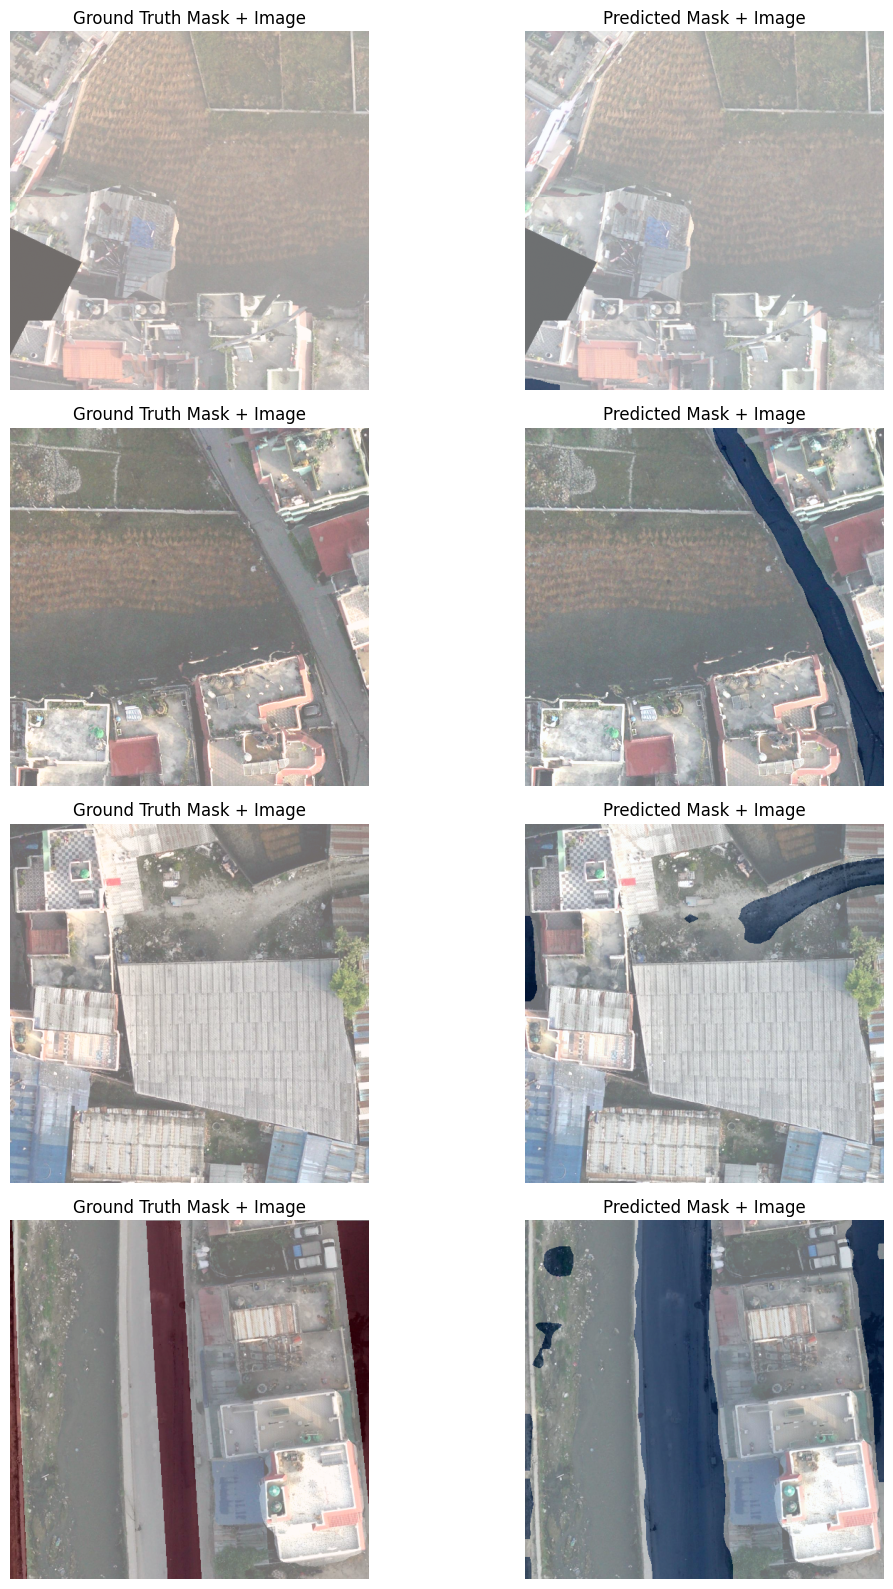

In [35]:
visualize_predictions(my_segmentation_model, test_loader, num_samples=4, threshold=0.5)